# Лабораторная работа №6
## Дискретное преобразование Фурье

**Вариант: 5**

Работа выполнена в среде Python (NumPy / Matplotlib).
Каждая функция, строящая график, дополнительно **сохраняет его в папку
проекта** `source/`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

rng = np.random.default_rng()
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

FIG_DIR = os.path.expanduser("~/University/TnAofDSP/lab6/source")
os.makedirs(FIG_DIR, exist_ok=True)

def save_and_show(fig=None, name="figure"):
    if fig is None:
        fig = plt.gcf()
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[график сохранён: {path}]")

---
# Часть 2. Программная

## 2.1. Собственная реализация ДПФ
Сгенерируйте сигнал своего варианта и постройте его график с подписанными осями.
Разработайте функцию `myDFT`, вычисляющую ДПФ по определению (5), не используя `fft`. Найдите спектр сигнала и постройте амплитудный и фазовый спектр в реальных частотах по формуле (22).

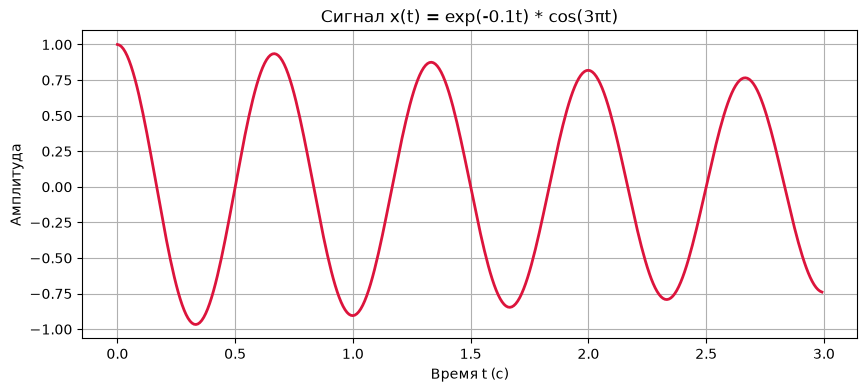

[график сохранён: /home/stanislau/University/TnAofDSP/lab6/source/2_1_signal.png]


In [2]:
fs = 120
T = 3.0
N = int(fs * T)
n = np.arange(N)
t = n / fs

x = np.exp(-0.1 * t) * np.cos(3 * np.pi * t)

fig = plt.figure(figsize=(10, 4))
plt.plot(t, x, color="crimson", lw=2)
plt.xlabel("Время t (с)")
plt.ylabel("Амплитуда")
plt.title("Сигнал x(t) = exp(-0.1t) * cos(3πt)")
save_and_show(fig, name="2_1_signal")

In [3]:
def myDFT(x):
    N = len(x)
    X = np.zeros(N, dtype=complex)
    for k in range(N):
        s = 0
        for n in range(N):
            s = s + x[n] * np.exp(-2j * np.pi * k * n / N)
        X[k] = s
    return X

X = myDFT(x)

k = np.arange(N)
f_k = k * fs / N

amp = np.abs(X)
phase = np.angle(X)

print("Шаг по частоте:", fs / N, "Гц")
print("Расхождение с np.fft.fft:", np.max(np.abs(X - np.fft.fft(x))))
print("Проверка X(N-k) = X*(k):", np.allclose(X[1:], np.conj(X[:0:-1])))

Шаг по частоте: 0.3333333333333333 Гц
Расхождение с np.fft.fft: 8.28782713068281e-12
Проверка X(N-k) = X*(k): True


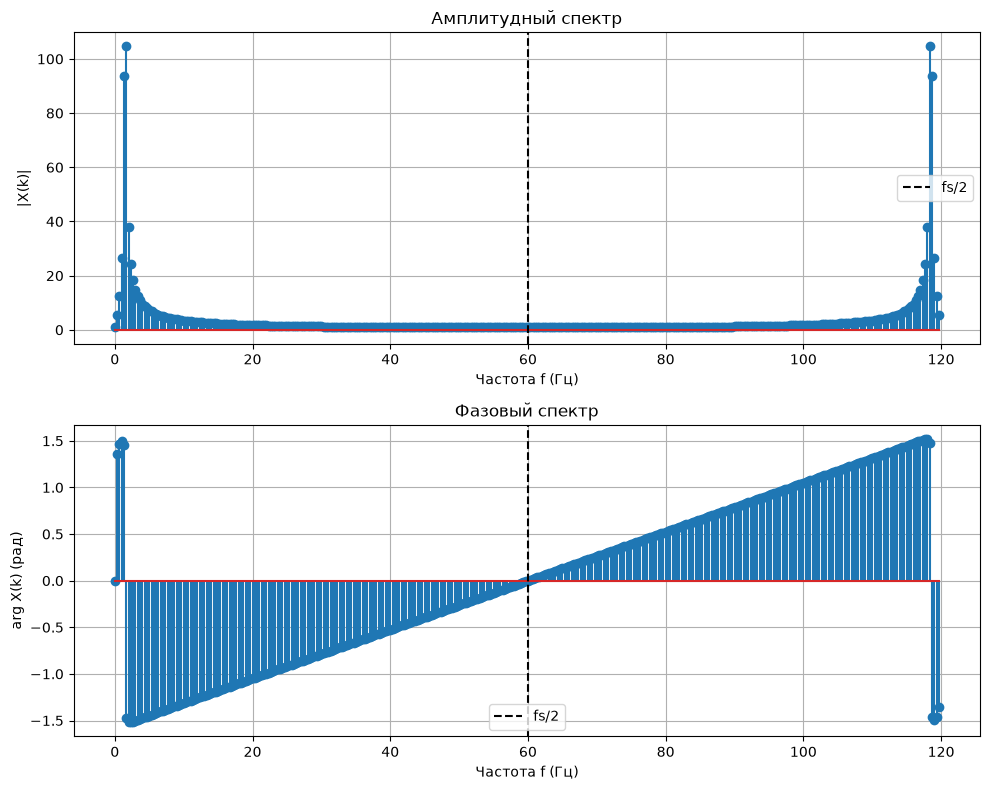

[график сохранён: /home/stanislau/University/TnAofDSP/lab6/source/2_1_spectrum.png]


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].stem(f_k, amp)
axes[0].axvline(fs / 2, color="black", linestyle="--", label="fs/2")
axes[0].set_xlabel("Частота f (Гц)")
axes[0].set_ylabel("|X(k)|")
axes[0].set_title("Амплитудный спектр")
axes[0].legend()

axes[1].stem(f_k, phase)
axes[1].axvline(fs / 2, color="black", linestyle="--", label="fs/2")
axes[1].set_xlabel("Частота f (Гц)")
axes[1].set_ylabel("arg X(k) (рад)")
axes[1].set_title("Фазовый спектр")
axes[1].legend()

plt.tight_layout()
save_and_show(fig, name="2_1_spectrum")

In [5]:
half = N // 2
k_max = np.argmax(amp[:half + 1])
print("Главный пик: k =", k_max, ", f =", f_k[k_max], "Гц")
print("Соседние отсчёты:")
for kk in range(k_max - 1, k_max + 2):
    print("k =", kk, ", f =", round(f_k[kk], 3), "Гц, |X| =", round(amp[kk], 3))

Главный пик: k = 5 , f = 1.6666666666666667 Гц
Соседние отсчёты:
k = 4 , f = 1.333 Гц, |X| = 93.557
k = 5 , f = 1.667 Гц, |X| = 104.589
k = 6 , f = 2.0 Гц, |X| = 37.998


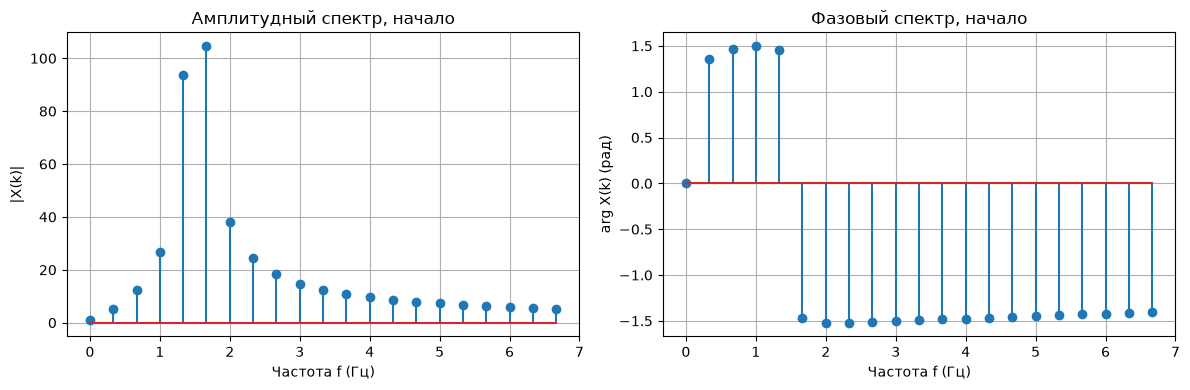

[график сохранён: /home/stanislau/University/TnAofDSP/lab6/source/2_1_spectrum_zoom.png]


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].stem(f_k[:21], amp[:21])
axes[0].set_xlabel("Частота f (Гц)")
axes[0].set_ylabel("|X(k)|")
axes[0].set_title("Амплитудный спектр, начало")

axes[1].stem(f_k[:21], phase[:21])
axes[1].set_xlabel("Частота f (Гц)")
axes[1].set_ylabel("arg X(k) (рад)")
axes[1].set_title("Фазовый спектр, начало")

plt.tight_layout()
save_and_show(fig, name="2_1_spectrum_zoom")

## 2.2. Применение свойства ДПФ
Сдвиг во временной области. Сдвиньте сигнал на $m = 20$ отсчётов, не переставляя его отсчёты напрямую: найдите $X(k)$, умножьте спектр на $e^{-j2\pi km/N}$ согласно (17), вычислите обратное ДПФ. Постройте исходный и полученный сигнал на одном графике. Сравните результат с `circshift(x, m)`.

In [7]:
m = 30

X_shift = X * np.exp(-2j * np.pi * k * m / N)
x_shift = np.real(np.fft.ifft(X_shift))

x_roll = np.roll(x, m)

print("Максимальная мнимая часть после ifft:", np.max(np.abs(np.imag(np.fft.ifft(X_shift)))))
print("Максимальное расхождение с np.roll:", np.max(np.abs(x_shift - x_roll)))

Максимальная мнимая часть после ifft: 9.517810083976555e-14
Максимальное расхождение с np.roll: 7.72715225139109e-14


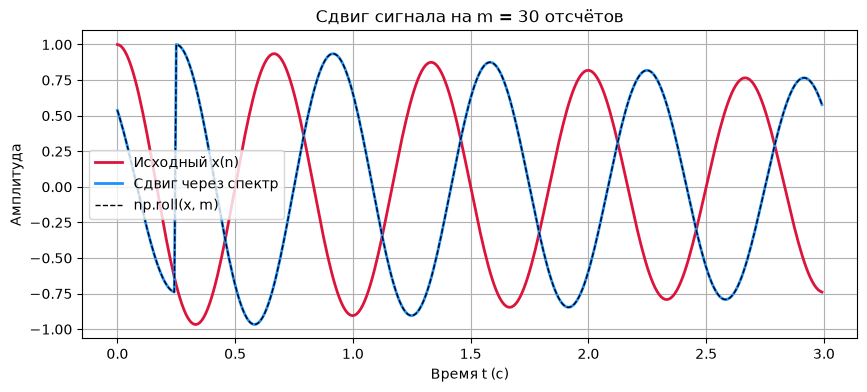

[график сохранён: /home/stanislau/University/TnAofDSP/lab6/source/2_2_shift.png]


In [8]:
fig = plt.figure(figsize=(10, 4))
plt.plot(t, x, color="crimson", lw=2, label="Исходный x(n)")
plt.plot(t, x_shift, color="dodgerblue", lw=2, label="Сдвиг через спектр")
plt.plot(t, x_roll, color="black", linestyle="--", lw=1, label="np.roll(x, m)")
plt.xlabel("Время t (с)")
plt.ylabel("Амплитуда")
plt.title("Сдвиг сигнала на m = 30 отсчётов")
plt.legend()
save_and_show(fig, name="2_2_shift")

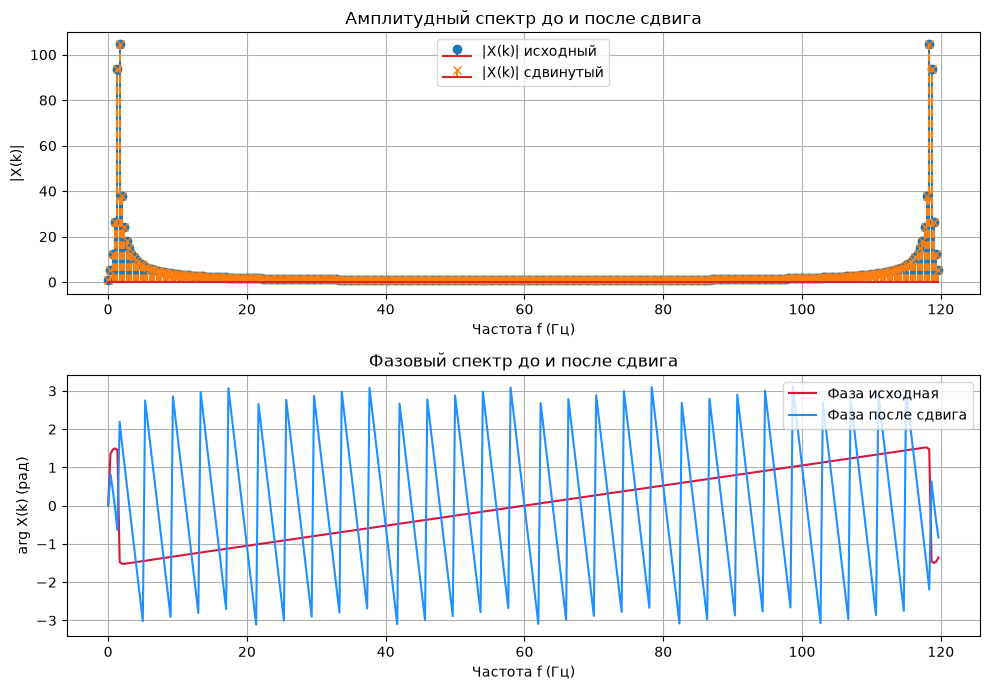

[график сохранён: /home/stanislau/University/TnAofDSP/lab6/source/2_2_shift_spectrum.png]


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].stem(f_k, np.abs(X), linefmt="C0-", markerfmt="C0o", label="|X(k)| исходный")
axes[0].stem(f_k, np.abs(X_shift), linefmt="C1--", markerfmt="C1x", label="|X(k)| сдвинутый")
axes[0].set_xlabel("Частота f (Гц)")
axes[0].set_ylabel("|X(k)|")
axes[0].set_title("Амплитудный спектр до и после сдвига")
axes[0].legend()

axes[1].plot(f_k, np.angle(X), color="crimson", label="Фаза исходная")
axes[1].plot(f_k, np.angle(X_shift), color="dodgerblue", label="Фаза после сдвига")
axes[1].set_xlabel("Частота f (Гц)")
axes[1].set_ylabel("arg X(k) (рад)")
axes[1].set_title("Фазовый спектр до и после сдвига")
axes[1].legend()

plt.tight_layout()
save_and_show(fig, name="2_2_shift_spectrum")

## 2.3. Спектральный анализ реального сигнала
**А. Анализ ЭКГ.** Синтезируйте сигнал электрокардиограммы по модели из приложения А с частотой дискретизации 360 Гц и длительностью 10 с. Пульс возьмите равным 72 ударам в минуту.
1. Постройте график сигнала и его амплитудный спектр в реальных частотах.
2. Определите по спектру частоту пульса. Ответ должен совпасть с заданным с точностью лучше 0,15 Гц.
3. Найдите в спектре сетевую наводку 50 Гц. Во сколько раз её пик выше медианного уровня спектра?

In [10]:
fs = 360
dur = 10
hr = 72

N = int(fs * dur)
t = np.arange(N) / fs

fb = hr / 60
ph = np.mod(t * fb, 1)

w = np.array([[0.10, 0.12, 0.025],
              [0.22, -0.15, 0.008],
              [0.25, 1.00, 0.008],
              [0.28, -0.25, 0.008],
              [0.42, 0.25, 0.035]])

x = np.zeros(N)
for i in range(w.shape[0]):
    d = np.minimum(np.abs(ph - w[i, 0]), 1 - np.abs(ph - w[i, 0]))
    x = x + w[i, 1] * np.exp(-0.5 * (d / w[i, 2]) ** 2)

x = x + 0.08 * np.sin(2 * np.pi * 50 * t) + 0.01 * rng.standard_normal(N)

X = np.fft.fft(x)
half = N // 2
k = np.arange(half + 1)
f = k * fs / N
amp = np.abs(X[:half + 1])

print("Число отсчётов N =", N)
print("Разрешение по частоте:", fs / N, "Гц")

Число отсчётов N = 3600
Разрешение по частоте: 0.1 Гц


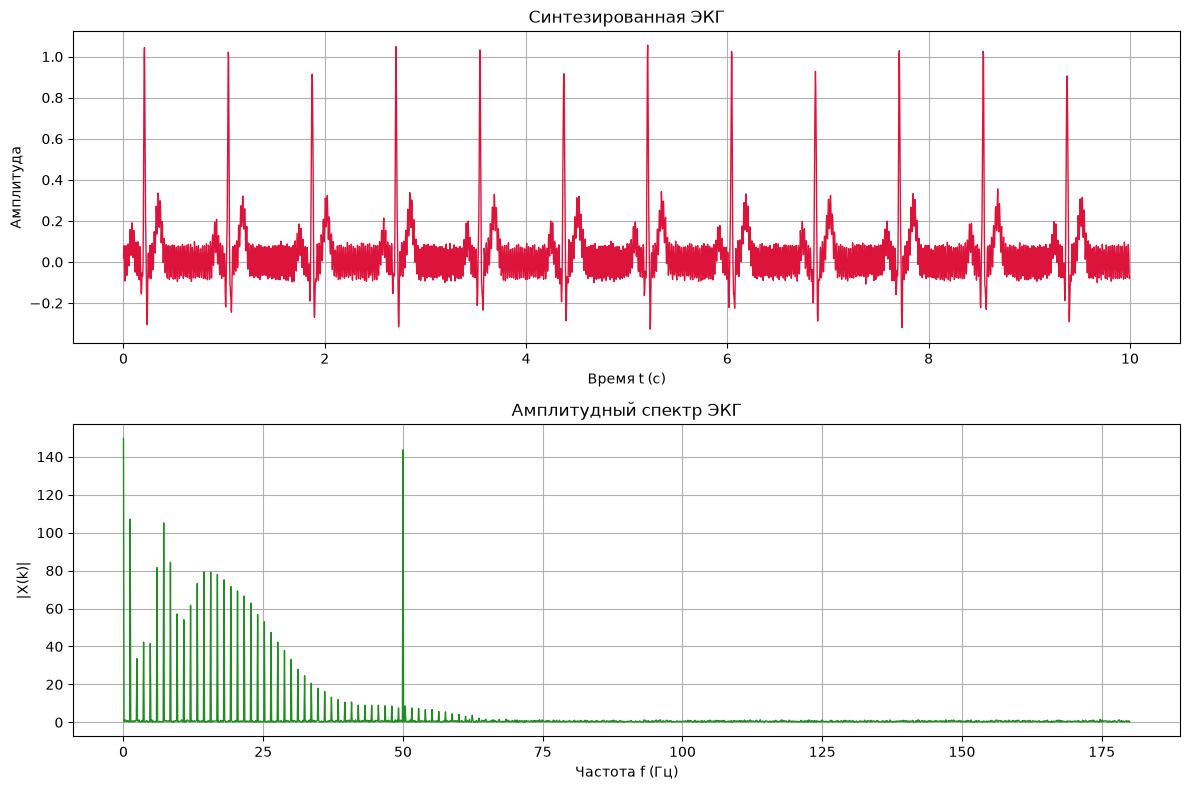

[график сохранён: /home/stanislau/University/TnAofDSP/lab6/source/2_3_ecg_signal_spectrum.png]


In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(t, x, color="crimson", lw=1)
axes[0].set_xlabel("Время t (с)")
axes[0].set_ylabel("Амплитуда")
axes[0].set_title("Синтезированная ЭКГ")

axes[1].plot(f, amp, color="forestgreen", lw=1)
axes[1].set_xlabel("Частота f (Гц)")
axes[1].set_ylabel("|X(k)|")
axes[1].set_title("Амплитудный спектр ЭКГ")

plt.tight_layout()
save_and_show(fig, name="2_3_ecg_signal_spectrum")

In [12]:
mask = (f >= 0.5) & (f <= 2.0)
i_pulse = np.argmax(amp[mask])
f_pulse = f[mask][i_pulse]

print("Частота пульса по спектру:", f_pulse, "Гц")
print("Пульс по спектру:", f_pulse * 60, "уд/мин")
print("Заданный пульс:", fb, "Гц")
print("Ошибка:", abs(f_pulse - fb), "Гц")

k_50 = int(round(50 * N / fs))
peak_50 = amp[k_50]
median_level = np.median(amp)

print("Индекс k для 50 Гц:", k_50, ", f =", f[k_50], "Гц")
print("Пик на 50 Гц:", peak_50)
print("Медианный уровень спектра:", median_level)
print("Отношение пика к медиане:", peak_50 / median_level)

Частота пульса по спектру: 1.2 Гц
Пульс по спектру: 72.0 уд/мин
Заданный пульс: 1.2 Гц
Ошибка: 0.0 Гц
Индекс k для 50 Гц: 500 , f = 50.0 Гц
Пик на 50 Гц: 143.59145540458815
Медианный уровень спектра: 0.5113097049821059
Отношение пика к медиане: 280.8306863833405


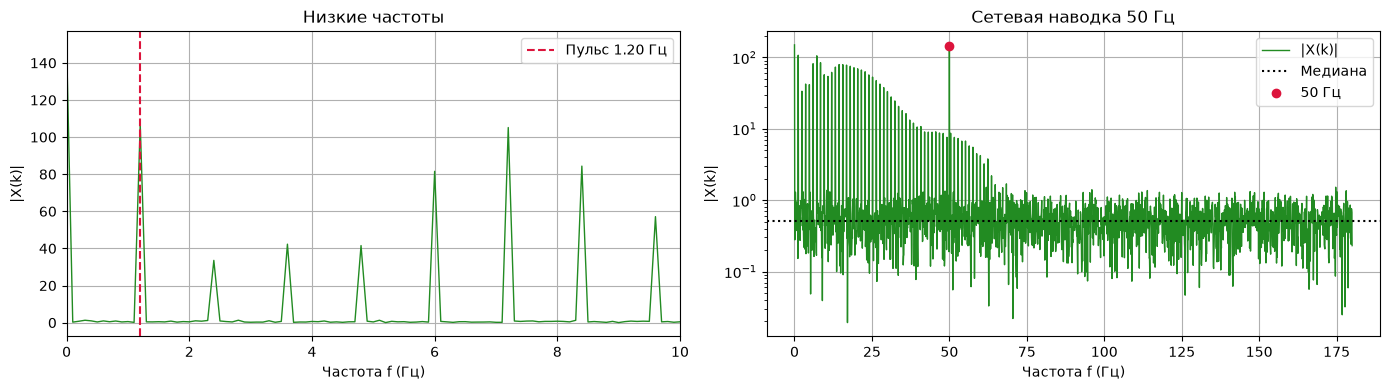

[график сохранён: /home/stanislau/University/TnAofDSP/lab6/source/2_3_ecg_pulse_and_50hz.png]


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(f, amp, color="forestgreen", lw=1)
axes[0].axvline(f_pulse, color="crimson", linestyle="--", label=f"Пульс {f_pulse:.2f} Гц")
axes[0].set_xlim(0, 10)
axes[0].set_xlabel("Частота f (Гц)")
axes[0].set_ylabel("|X(k)|")
axes[0].set_title("Низкие частоты")
axes[0].legend()

axes[1].plot(f, amp, color="forestgreen", lw=1, label="|X(k)|")
axes[1].axhline(median_level, color="black", linestyle=":", label="Медиана")
axes[1].scatter([f[k_50]], [peak_50], color="crimson", zorder=3, label="50 Гц")
axes[1].set_yscale("log")
axes[1].set_xlabel("Частота f (Гц)")
axes[1].set_ylabel("|X(k)|")
axes[1].set_title("Сетевая наводка 50 Гц")
axes[1].legend()

plt.tight_layout()
save_and_show(fig, name="2_3_ecg_pulse_and_50hz")